[496.485, 731.7990000000001, 904.995, 1324.98, 1309.5269999999998, 1362.312, 1422.441, 1461.762, 1499.094, 1489.761, 1593.954, 1529.847]


/tmp/ipykernel_746310/194946006.py:22: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  resources = pd.read_csv(file, delimiter=", ")
/tmp/ipykernel_746310/194946006.py:22: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  resources = pd.read_csv(file, delimiter=", ")
/tmp/ipykernel_746310/194946006.py:58: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  timing_hand = pd.read_csv(handfile, delimiter=", ")["Timing"]
/tmp/i

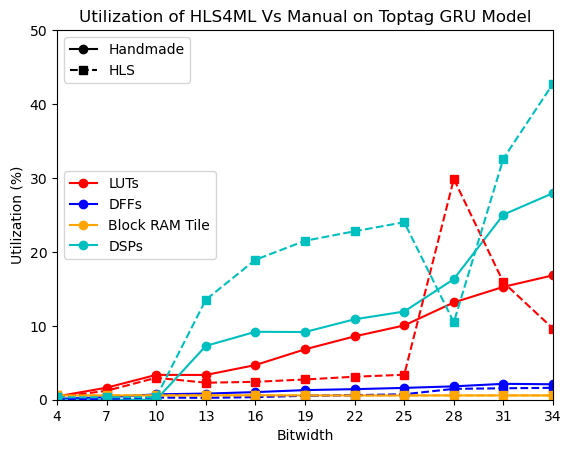

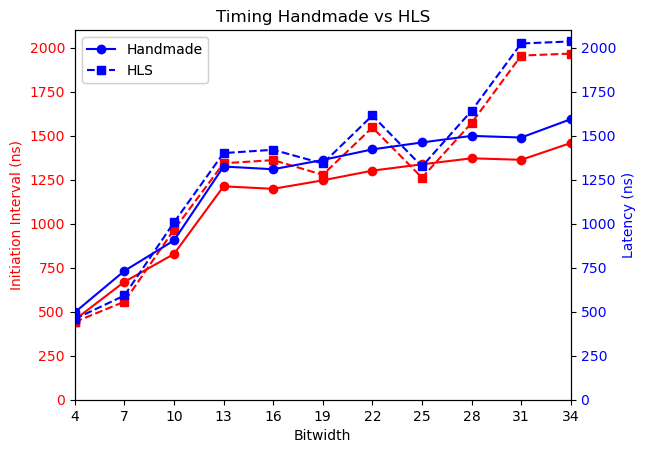

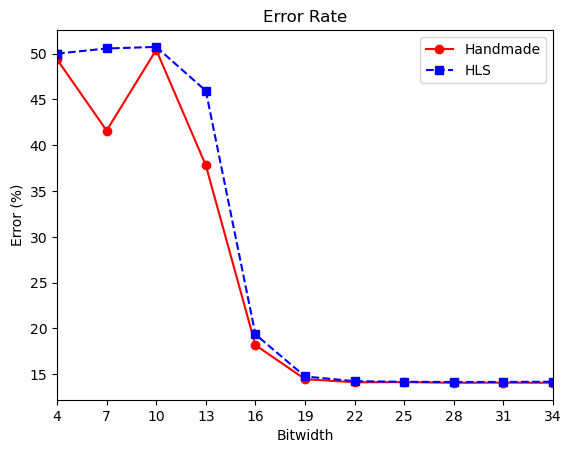

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
legend_lines = []
# hand_lat = [23, 19, 16]
resf, res = plt.subplots()

timingf, timing = plt.subplots()

accf, acc = plt.subplots()
# latf, lat = plt.subplots()
lat = timing.twinx()

marker_styles = [None,'o', 's', 'D', '^', 'v', '<', '>', 'p', '*', 'h', 'H', '+', 'x', '|', '_']
line_styles = ['-', '--', '-.', ':']
colors = ['r','b',(255.0/255,165.0/255,0),'c','m','g']
j=[0, 1]
timings = []
renames = {"Slice Registers":"DFFs", "Slice LUTs":"LUTs"}
# colorkey = {"LUTs":'r', "DFFs": 'y', "DSPs": }
def plot_res(file, ls, name, marker, color_sel=None):
    resources = pd.read_csv(file, delimiter=", ")
    x_val = resources["Bits"]
    all_res_hand = []
    Nono = "Bits Accuracy Timing Bonded IOB CycleLatency TotalLatency BlockRAMTile"
    i=0
    timings.append((resources["Timing"], name))
    # timing.plot(x_val, 10-resources["Timing"], label=name, linestyle=ls, color=colors[j[0]], marker=marker)
    acc.plot(x_val, (1-resources["Accuracy"])*100, label=name, linestyle=ls, color=colors[j[0]], marker=marker)
    j[0]=(j[0]+1)%len(colors)
    for key in resources:
        if (key not in Nono):
            all_res_hand.append(resources[key])
            nam = key if key not in renames else renames[key]
            res.plot(x_val, 
            resources[key], 
            label=(nam if len(legend_lines)==0  else None), 
            linestyle=ls, 
            color=colors[i%len(colors)] if color_sel==None else color_sel,
            marker=marker)
            i+=1
            
    legend_lines.append((name, ls, marker,color_sel))
cycle_ii_hand = 140
cycle_lat_hand = cycle_ii_hand+13

# plot_res("LSTM-Handmade/Results/util_Toptag_my_mult.csv", '-', "Handmade",marker_styles[1] )
# plot_res("LSTM-hls/results/util_hls_iitest.csv", '--', "HLS",marker_styles[2] )
plot_res("GRU-Handmade/Results/util_caleb_sweep.csv", '-', "Handmade",marker_styles[1] )
plot_res("GRU-HLS/results/util_hls_toptag_gru_fullsweep.csv", '--', "HLS",marker_styles[2] )
# # print(latency)


hlsfile = "GRU-HLS/results/util_hls_toptag_gru_fullsweep.csv"
handfile = "GRU-Handmade/Results/util_caleb_sweep.csv"
total_latency_hand = []
total_ii_hand = []
timing_hand = pd.read_csv(handfile, delimiter=", ")["Timing"]
bits  = pd.read_csv(handfile, delimiter=", ")["Bits"]
for tim in timing_hand:
    # tim_f = 10-float(tim)
    tim_f = tim
    total_latency_hand.append(tim_f*cycle_lat_hand)
    total_ii_hand.append(tim_f*cycle_ii_hand)
print(total_latency_hand)
lat.plot(bits, total_latency_hand, label="Handmade", color = 'b',marker=marker_styles[1])
timing.plot(bits, total_ii_hand, label="Handmade", color = 'r',marker=marker_styles[1])

bits  = pd.read_csv(hlsfile, delimiter=", ")["Bits"]
total_latency_hls = pd.read_csv(hlsfile, delimiter=", ")["Total Latency"]
total_ii_hls = pd.read_csv(hlsfile, delimiter=", ")["Total II"]
lat.plot(bits, total_latency_hls, label="HLS", color = 'b', linestyle='--',marker=marker_styles[2])
timing.plot(bits, total_ii_hls, label="HLS", color = 'r', linestyle='--',marker=marker_styles[2])
timing.tick_params(axis='y', labelcolor='r')

#print()

lat.legend(loc='upper left')
lat.set_xticks(np.arange(4, 40, 3))
lat.set_ylim((0,2100))
lat.set_xlim((4,34))
# lat.set_title("Total Latency")
# lat.set_xlabel("Bitwidth")
lat.set_ylabel("Latency (ns)", color='b')
lat.tick_params(axis='y', labelcolor='b')

timing.legend(loc='upper left')
timing.set_title("Timing Handmade vs HLS")
timing.set_xlabel("Bitwidth")
timing.set_ylabel("Initiation Interval (ns)", color='r')
timing.set_ylim((0,2100))
timing.set_xticks(np.arange(4, 40, 3))
timing.set_xlim((4,34))




first_legend = res.legend(loc='center left')
res.add_artist(first_legend)
lines = []
for line in legend_lines:
    l, = res.plot([], label=line[0], linestyle=line[1], marker=line[2], color=line[3] if line[3]!=None else (0,0,0))
    lines.append(l)
res.legend(handles=lines, loc='upper left')
res.set_title("Utilization of HLS4ML Vs Manual on Toptag GRU Model")
res.set_xticks(np.arange(4, 40, 3))
res.set_xlim((4,34))
res.set_ylim((0,50))
res.set_xlabel("Bitwidth")
res.set_ylabel("Utilization (%)")


acc.legend(loc='upper right')
acc.set_title("Error Rate")
acc.set_xlabel("Bitwidth")
acc.set_ylabel("Error (%)")
acc.set_xticks(np.arange(4, 40, 3))
acc.set_xlim((4,34))






plt.show()


In [12]:
def comp(a, b):
    comps = [0.0]*len(a)
    for i in range(min(len(a),len(b))):
        comps[i]=b[i]/a[i]
    return np.round(np.average(comps),4)
def mklist(item):
    output = [0.0]*len(item)
    for i,item in enumerate(item):
        output[i]=item
    return output
def list_to_float(list):
    return np.array([float(i) for i in list])
res_hls = pd.read_csv("LSTM-hls/results/util_hls_iitest.csv", delimiter=", ")
res_hand = pd.read_csv("LSTM-Handmade/Results/util_Toptag_my_mult.csv", delimiter=", ")


start=3
end=14

max_hls = np.max(np.stack((res_hls["Slice LUTs"],res_hls["DSPs"]), axis=1), axis=1)
max_hand = np.max(np.stack((res_hand["Slice LUTs"],res_hand["DSPs"]), axis=1), axis=1)
ratios = np.divide(max_hand[start:len(max_hls)], max_hls[start:])

cycle_ii_hand = 141
cycle_lat_hand = cycle_ii_hand+13

max_ratio = np.min(ratios)
ind_rat = -1
print(ratios)
for i in range(len(ratios)):
    if ratios[i]==max_ratio:
        ind_rat=i
print(f"Max ratio in device utilization was {np.round(max_ratio,4)} at {list(res_hls['Bits'])[start:][ind_rat]}")
print(f"Average max device resource: {comp(max_hls[start:end], max_hand[start:end])}")
latency_hls = res_hls["Total Latency"]
ii_hls = res_hls["Total II"]
latency_hand = (10-list_to_float(res_hand["Timing"]))*cycle_lat_hand
ii_hand = (10-list_to_float(res_hand["Timing"]))*cycle_ii_hand

print("Initiation Interval: " + f"{comp(mklist(ii_hls)[start:], mklist(ii_hand)[start:])}")
print("Latency: " + f"{comp(mklist(latency_hls)[start:], mklist(latency_hand)[start:])}")
# print(np.average(np.divide(max_hand[:9],max_hls)))
for key in res_hand:
    if (key not in "Bits BlockRAMTile Bits SliceRegisters BondedIOB"):
        print(key + ": " + f"{comp(mklist(res_hls[key])[start:], mklist(res_hand[key])[start:])}")
        # hand = mklist(res_hand[key])
        # hls = mklist(res_hls[key])
        # print(f"{key}: HLS:{np.mean(hls[start:end])} Hand:{np.mean(hand[start:end])}")
        # comped = comp((res_hls[key]), (res_hand[key]))
        # print(f"Hand is {np.round(comped, 4)} higher than HLS at {key}")

[0.47818648 0.4017769  0.36657359 0.42033272 0.48502994 0.4142965
 0.80601555 0.62106136]
Max ratio in device utilization was 0.3666 at 19
Average max device resource: 0.4992
Initiation Interval: 0.7948
Latency: 0.8366
Slice LUTs: 1.984
Slice Registers: 2.4066
Block RAM Tile: 0.1793
DSPs: 0.9062
Bonded IOB: 1.1585
Timing: 4.3503
Accuracy: 0.9924


/tmp/ipykernel_4116871/3387284849.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  res_hls = pd.read_csv("LSTM-hls/results/util_hls_iitest.csv", delimiter=", ")
/tmp/ipykernel_4116871/3387284849.py:14: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  res_hand = pd.read_csv("LSTM-Handmade/Results/util_Toptag_my_mult.csv", delimiter=", ")


In [ ]:
print("Initiation Interval: " + f"{comp(mklist(ii_hls)[start:], mklist(ii_hand)[start:])}")